# 07 — Partie E : fine-tuning

### E1 : `roberta-base` et `microsoft/deberta-v3-base`
Entrée « conclusion [SEP] position [SEP] prémisse », perte pondérée, seuil sur val. lr 2e-5, batch 32, warmup 10 %, weight decay 0,01, fp16, 3 graines (`scripts/run_E.py`, `src/valeval/plm.py`).
Le point de départ de la fiche est de 3 à 5 époques. Les scores montant encore à l'époque 5, on teste aussi 8 époques.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold
from valeval.data import VALUES, label_matrix, load_split
from valeval.evaluate import f1_par_valeur, scores, seuil_unique, seuils_par_valeur

RUNS = Path("../cache/runs")
GRAINES = (42, 43, 44)
va = load_split("validation")
y_va, y_tr = label_matrix(va), label_matrix(load_split("training"))

def croise(p):
    u, v = np.zeros_like(y_va), np.zeros_like(y_va)
    for a, b in GroupKFold(5).split(p, groups=va.conclusion):
        u[b] = p[b] >= seuil_unique(y_va[a], p[a])
        v[b] = p[b] >= seuils_par_valeur(y_va[a], p[a])
    return scores(y_va, u)["macro_f1"], scores(y_va, v)["macro_f1"]

config = {"RoBERTa, 5 époques": "E1_roberta", "RoBERTa, 8 époques": "E1_roberta_ep8",
          "DeBERTa, 5 époques": "E1_deberta", "DeBERTa, 8 époques": "E1_deberta_ep8"}
lignes, ps, jsons = [], {}, {}
for titre, n in config.items():
    rs = [json.loads((RUNS / f"{n}_seed{g}.json").read_text(encoding="utf-8")) for g in GRAINES]
    ps[titre] = [np.load(RUNS / f"{n}_seed{g}_val.npy") for g in GRAINES]
    jsons[titre] = rs
    f = [r["macro_f1"] for r in rs]
    cr = [croise(p) for p in ps[titre]]
    lignes.append({"modèle": titre, "42": f[0], "43": f[1], "44": f[2], "moyenne": np.mean(f), "écart-type": np.std(f, ddof=1),
                   "croisé unique": np.mean([c[0] for c in cr]), "croisé par valeur": np.mean([c[1] for c in cr]),
                   "temps moyen (s)": round(np.mean([r["temps_s"] for r in rs]))})
e1 = pd.DataFrame(lignes)
e1.round(3)

,modèle,42,43,44,moyenne,écart-type,croisé unique,croisé par valeur,temps moyen (s)
0,"RoBERTa, 5 époques",0.480,0.474,0.473,0.476,0.004,0.475,0.474,121
1,"RoBERTa, 8 époques",0.488,0.481,0.480,0.483,0.004,0.480,0.477,193
2,"DeBERTa, 5 époques",0.455,0.454,0.445,0.451,0.005,0.448,0.447,193
3,"DeBERTa, 8 époques",0.466,0.467,0.464,0.466,0.002,0.463,0.459,296


C:\Users\ayoub\AppData\Local\Temp\ipykernel_45132\3447661373.py:3: Pandas4Warning: Constructing a DataFrame from a list of sequences with mismatched lengths is deprecated and will raise in a future version. The shorter sequences are currently padded with NaN; make all sequences the same length before constructing instead.
  c = pd.DataFrame([[e["macro_f1_val"] for e in r["courbes"]] for r in jsons[titre]])   # NaN si arrêt anticipé


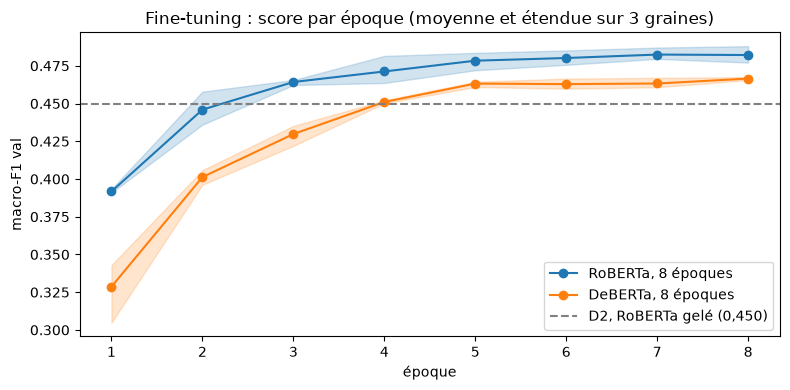

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
for titre, couleur in [("RoBERTa, 8 époques", "tab:blue"), ("DeBERTa, 8 époques", "tab:orange")]:
    c = pd.DataFrame([[e["macro_f1_val"] for e in r["courbes"]] for r in jsons[titre]])   # NaN si arrêt anticipé
    x = np.arange(1, c.shape[1] + 1)
    ax.plot(x, c.mean(), marker="o", color=couleur, label=titre)
    ax.fill_between(x, c.min(), c.max(), color=couleur, alpha=.2)
ax.axhline(.450, color="gray", ls="--", label="D2, RoBERTa gelé (0,450)")
ax.set(xlabel="époque", ylabel="macro-F1 val", title="Fine-tuning : score par époque (moyenne et étendue sur 3 graines)")
ax.legend(); plt.tight_layout(); plt.savefig("../figures/E1_courbes.png", dpi=120); plt.show()

### Gelé ou fine-tuné (Q8)

In [3]:
pd.DataFrame([
    {"modèle": "D1 RoBERTa gelé + LR", "macro-F1 val": .446, "paramètres entraînés": 20 * 769, "temps d'entraînement (s)": "~17 (extraction 15 + LR 2)"},
    {"modèle": "D2 RoBERTa gelé + BiLSTM + attention", "macro-F1 val": .450, "paramètres entraînés": 957716, "temps d'entraînement (s)": "~95 (extraction 15 + tête 80)"},
    {"modèle": "E1 RoBERTa, 8 époques", "macro-F1 val": e1.moyenne[1], "paramètres entraînés": jsons["RoBERTa, 8 époques"][0]["params"], "temps d'entraînement (s)": "~193"},
]).round(3)

,modèle,macro-F1 val,paramètres entraînés,temps d'entraînement (s)
0,D1 RoBERTa gelé + LR,0.446,15380,~17 (extraction 15 + LR 2)
1,D2 RoBERTa gelé + BiLSTM + attention,0.450,957716,~95 (extraction 15 + tête 80)
2,"E1 RoBERTa, 8 époques",0.483,124661012,~193


### F1 par valeur

In [4]:
def moyen(liste):
    return pd.DataFrame([f1_par_valeur(y_va, p >= seuil_unique(y_va, p)) for p in liste]).mean()

d2 = [np.load(RUNS / f"D2_seed{g}_val.npy") for g in GRAINES]
c1 = [np.load(RUNS / f"C1_glove_max_seed{g}_val.npy") for g in GRAINES]
parv = pd.DataFrame({"n_train": pd.Series(dict(zip(VALUES, y_tr.sum(0)))), "C1": moyen(c1), "D2": moyen(d2),
                     "E1 RoBERTa": moyen(ps["RoBERTa, 8 époques"]), "E1 DeBERTa": moyen(ps["DeBERTa, 8 époques"])})
parv["E1 - D2"] = parv["E1 RoBERTa"] - parv["D2"]
parv.sort_values("E1 RoBERTa", ascending=False).round(3)

,n_train,C1,D2,E1 RoBERTa,E1 DeBERTa,E1 - D2
Security: personal,2000,0.690,0.717,0.738,0.716,0.021
Universalism: nature,427,0.654,0.672,0.708,0.660,0.037
Universalism: concern,2081,0.582,0.645,0.661,0.640,0.016
Security: societal,1728,0.577,0.629,0.659,0.641,0.030
Achievement,1512,0.593,0.631,0.651,0.639,0.020
Benevolence: caring,1332,0.570,0.574,0.589,0.575,0.014
Conformity: rules,1177,0.517,0.536,0.559,0.561,0.023
Self-direction: action,1395,0.472,0.545,0.556,0.562,0.011
Power: resources,625,0.466,0.514,0.513,0.433,-0.001
Self-direction: thought,988,0.403,0.474,0.506,0.486,0.032


**Lecture (Q8) :**
- **Fine-tuné vs gelé :** RoBERTa passe de 0,450 (D2) à **0,483** (8 époques), soit +0,033. Coût : 124,7 millions de paramètres entraînés contre 15 000 à 958 000, et ~193 s contre ~17 à 95 s.
- **Le gain touche presque toutes les valeurs :** surtout *Face* (+0,12), *Stimulation* (+0,09), *Humility* (+0,07). *Power: dominance* et *Power: resources* ne bougent pas. *Humility* reste la plus basse (0,205).
- **RoBERTa ou DeBERTa :** RoBERTa, sur ces réglages : 0,483 ± 0,004 contre 0,466 ± 0,002, devant à chaque époque, avec 1,5 fois moins de paramètres et 1,5 fois moins de temps. Limite : seuls les réglages de départ ont été testés ; un autre taux d'apprentissage pourrait changer l'écart pour DeBERTa.
- **Époques :** 8 époques apportent +0,007 pour RoBERTa et +0,015 pour DeBERTa par rapport à 5, à chacune des 3 graines. Les courbes se stabilisent après l'époque 5.
- **Seuils :** le seuil par valeur n'apporte rien en validation croisée (0,477 contre 0,480). On garde le seuil unique.

**Décision E1 :** RoBERTa, 8 époques, seuil unique. Macro-F1 honnête sur val : **0,480**.